### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC

from qiskit.circuit.library import zz_feature_map
from qiskit.primitives import StatevectorSampler as Sampler

from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = 12345

### Part I - Generate and explore the dataset

[array([2.07345115, 5.84336234]), array([4.0212386 , 4.52389342]), array([1.94778745, 1.69646003]), array([3.95840674, 2.82743339]), array([4.27256601, 5.65486678]), array([2.136283  , 1.75929189]), array([3.83274304, 0.37699112]), array([2.45044227, 1.88495559]), array([5.96902604, 2.76460154]), array([5.02654825, 1.31946891]), array([4.77522083, 2.95309709]), array([6.1575216 , 1.69646003]), array([4.1469023 , 1.63362818]), array([5.2150438 , 3.01592895]), array([3.76991118, 3.0787608 ]), array([3.76991118, 5.2150438 ]), array([2.32477856, 3.83274304]), array([5.0893801 , 1.25663706]), array([2.07345115, 1.50796447]), array([2.136283  , 0.50265482])]


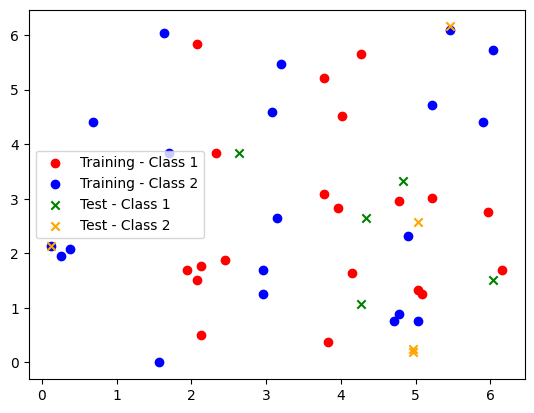

In [138]:
from matplotlib import legend

data = ad_hoc_data(training_size=20, n=2, test_size=5, gap=0.3)

train_classes = data[1]
test_classes = data[3]

train_class_1 = []
train_class_2 = []
test_class_1 = []
test_class_2 = []


for i in range(len(train_classes)):
  if train_classes[i][0] == 1:
    train_class_1.append(data[0][i])
  else:
    train_class_2.append(data[0][i])

for i in range(len(test_classes)):
  if test_classes[i][0] == 1:
    test_class_1.append(data[2][i])
  else:
    test_class_2.append(data[2][i])

print(train_class_1)

train_class_1 = np.array(train_class_1)
train_class_2 = np.array(train_class_2)
test_class_1 = np.array(test_class_1)
test_class_2 = np.array(test_class_2)

plt.scatter(train_class_1[:, 0], train_class_1[:, 1], label="Training - Class 1", marker="o", c="red")
plt.scatter(train_class_2[:, 0], train_class_2[:, 1], label="Training - Class 2", marker="o", c="blue")
plt.scatter(test_class_1[:, 0], test_class_1[:, 1], label="Test - Class 1", marker="x", c="green")
plt.scatter(test_class_2[:, 0], test_class_2[:, 1], label="Test - Class 2", marker="x", c="orange")

plt.legend()

**1. What is the shape of the training feature matrix ?**

There are 2 features for each sample, 20 samples per class and 2 classes so it's 40x2.

**2. What is the shape of the test feature matrix ?**

There are 2 features for each sample, 5 samples per class and 2 classes so it's 10x2.

**3. What is the range of the two input features ?**

x1 and x2 ranges from 0 to 2pi.

**4. Are the two classes linearly separable in the original two-dimensional feature space ?**

The two classes are not linearly separable because the points are all mixed up. Otherwise we would see for example every red points on the left and blue points on the right, or something similar with a distinct separation.

**5. What would you expect from a linear classifier applied directly to the original features ?**

It would not separate classes correctly. There would be points from both classe on both side of the linear line.

**6. Why might a kernel method be useful for this dataset ?**

It could convert the samples from non linear positions to linear positions, enabling the SVM to find plan to separate the classes.

### Part II - Construct a quantum feature map

In [139]:
feature_map = zz_feature_map(feature_dimension=2, reps=2, entanglement='linear')

In [140]:
print(feature_map)

   ┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐├───┤»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ H ├»
   └───┘└───────────┘└───┘└──────────────────────────────┘└───┘└───┘»
«   ┌───────────┐                                          
«0: ┤ P(2*x[0]) ├──■────────────────────────────────────■──
«   ├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐
«1: ┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├
«   └───────────┘└───┘└──────────────────────────────┘└───┘


**1. How many qubits are used ?**

2 qubits are used.

**2. How the classical features enter the circuit ?**

The classical features enter the circuit from the x parameter from the P gates.

**3. Which gates are used ?**

H, P and CNOT gates.

**4. Where entanglement is introduced ?**

Entanglement is introduced between the P gate that combines features x[0] and x[1].

**5. What changing the number of repetitions could potentially do to the feature map ?**

It could maybe enhance the precision of the feature map.

### Part III - Build the quantum kernel

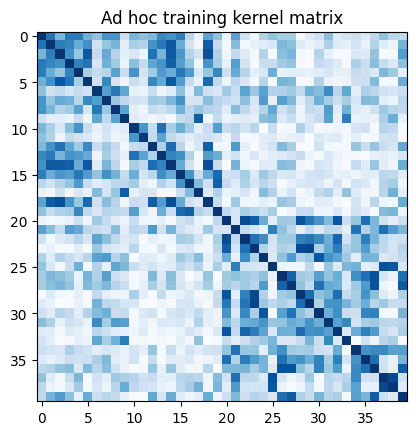

(40, 40)


In [141]:
adhoc_kernel = FidelityQuantumKernel(feature_map=feature_map, fidelity=ComputeUncompute(sampler=Sampler()))

train_features = np.array(data[0])

adhoc_matrix_train = adhoc_kernel.evaluate(x_vec=train_features)
plt.imshow(
  np.asmatrix(adhoc_matrix_train),
  interpolation="nearest",
  origin="upper",
  cmap="Blues"
)
plt.title("Ad hoc training kernel matrix")
plt.show()

print(adhoc_matrix_train.shape)

**1. What is the dimension of Ktrain ?**

Ktrain is 40x40. (because there are 40 training samples)

**2. Is Ktrain symmetric and why ?**

Ktrain is symetric because we only gave x_vec so it has calculed the self inner product. x and y axis are the same and |<phi(x)|phi(y)>|^2 = |<phi(y)|phi(x)>|^2

**3. What do the diagonal elements represent ?**

The diagonal elements represent |<phi(x)|phi(x)>|^2 which is equal to 1.

**4. What can we say about pair of points with larger kernel values ?**

The more 2 points have a large kernel value, the more it means that their representation is similar. So the more the points are similar the higher their probability to be in the same class.

**5. What can we say about pair of points with smaller kernel values?**

Conversely, the more 2 points have a small kernel value, the more it means that their representation is completely different. So the more the points are similar the higher their probability to be in a different class. (the more there are orthogonal)

**6. Why should your answers to the last two questions not be interpreted as a strict classification rule?**

The kernel value doesn't give the class of elements but is involved in the function to maximize that can finally give us the class.

### Part IV - Classification with a Support Vector Classifier (SVC)

In [142]:
SVC_model = SVC(kernel=adhoc_kernel.evaluate)

train_classes = []
for d in data[1]:
  if d[0] == 1:
    train_classes.append(0)
  else:
    train_classes.append(1)
train_classes = np.array(train_classes)

print(train_classes)

SVC_model.fit(train_features, train_classes)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1]


SVC(kernel=<bound method FidelityQuantumKernel.evaluate of <qiskit_machine_learning.kernels.fidelity_quantum_kernel.FidelityQuantumKernel object at 0x78fb650aab30>>)

In [143]:
test_set = data[2]
test_classes = []

for d in data[3]:
  if d[0] == 1:
    test_classes.append(0)
  else:
    test_classes.append(1)
test_classes = np.array(test_classes)

SVC_model.score(data[2], test_classes)

1.0

**1. Is the SVC itself a quantum algorithm ?**

No, SVC is a classical algorithm.

**2. What part of the SVC algorithm is classical ?**

Every parts of this algorithm is classical except the computation of the inner product.

**3. Where is the quantum computation used ?**

The quantum part is the computation of the kernel function (inner product) that we get from the function to maximize.

**4. What is the score you obtained on the test set ?**

The obtained score on the test set is 1.0.

**5. How do you explain this score ?**

The model didn't generelize well. The dataset is maybe to small or badly prepared. Maybe we could play on the gap parameter.

In [144]:
QSVC_model = QSVC(quantum_kernel=adhoc_kernel)
QSVC_model.fit(train_features, train_classes)
QSVC_model.score(data[2], test_classes)

1.0